<a href="https://colab.research.google.com/github/shikshita09/DataScienceEcosystem/blob/main/Multi_Agent_College_Chatbot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
!pip install -q langchain langchain-core langchain-community langchain-groq faiss-cpu pypdf


In [16]:
import os
from google.colab import userdata

# Retrieve your Groq or Gemini API key stored in Colab Secrets
# (In Colab sidebar -> Key icon -> Add secret "GROQ_API_KEY")
os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.embeddings import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough, RunnableLambda

In [17]:
# Create sample mock documents
admissions_text = """
College Admissions Policy:
1. Undergraduate Admission requires a minimum high school score of 75%.
2. Entrance exam (CET) rank under 10,000 is required for Computer Engineering.
3. Application Deadline for Fall Semester: July 31st. Application Fee: $50.
4. Tuition Fees: Computer Science - $12,000/year; Mechanical Engineering - $10,000/year.
"""

academics_text = """
College Academic Structure:
1. Computer Engineering Dept: Offers Courses in AI, Data Structures, Web Dev, and Operating Systems.
2. Mechanical Dept: Focuses on Thermodynamics, Robotics, and CAD/CAM.
3. Attendance Policy: Minimum 75% mandatory attendance required to appear in final exams.
4. Grading Scheme: Grade Point Average (GPA) is calculated out of 10.
"""

with open("admissions.txt", "w") as f:
    f.write(admissions_text)
with open("academics.txt", "w") as f:
    f.write(academics_text)

# Embeddings & Vector DB Initialization
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

def build_vector_store(file_path):
    with open(file_path, "r") as f:
        text = f.read()
    splitter = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=20)
    docs = splitter.create_documents([text])
    return FAISS.from_documents(docs, embeddings)

admissions_db = build_vector_store("admissions.txt")
academics_db = build_vector_store("academics.txt")

admissions_retriever = admissions_db.as_retriever(search_kwargs={"k": 2})
academics_retriever = academics_db.as_retriever(search_kwargs={"k": 2})

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [35]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0)


def format_docs(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# 1. Admissions Agent Chain
admissions_prompt = ChatPromptTemplate.from_template("""
You are the College Admissions Desk Agent. Answer the student query strictly using the provided context.
Context: {context}
Question: {question}
Answer:""")

admissions_chain = (
    {"context": admissions_retriever | format_docs, "question": RunnablePassthrough()}
    | admissions_prompt
    | llm
    | StrOutputParser()
)

# 2. Academics Agent Chain
academics_prompt = ChatPromptTemplate.from_template("""
You are the Academic Affairs Agent. Answer questions about curriculum, departments, and attendance.
Context: {context}
Question: {question}
Answer:""")

academics_chain = (
    {"context": academics_retriever | format_docs, "question": RunnablePassthrough()}
    | academics_prompt
    | llm
    | StrOutputParser()
)

# 3. General Agent Chain
general_prompt = ChatPromptTemplate.from_template("""
You are the College Welcome Desk Agent. Answer general queries, greetings, or campus info politely.
Question: {question}
Answer:""")

general_chain = general_prompt | llm | StrOutputParser()

In [36]:
router_prompt = ChatPromptTemplate.from_template("""
Categorize the following student query into exactly ONE category: 'admissions', 'academics', or 'general'.
Output ONLY the category name.

Examples:
Query: When is the deadline to pay tuition fees? -> admissions
Query: What subjects are taught in computer engineering? -> academics
Query: Hello, who are you? -> general

Query: {question}
Category:""")

# Ensure router uses the updated llm instance
router_chain = router_prompt | llm | StrOutputParser()

def route_and_execute(info):
    category = info['category'].strip().lower()
    question = info['question']

    print(f"📍 [Supervisor Router] Delegating to: Agent [{category.upper()}]")

    if "admission" in category:
        return admissions_chain.invoke(question)
    elif "academic" in category:
        return academics_chain.invoke(question)
    else:
        return general_chain.invoke(question)

# Complete Multi-Agent LCEL Chain
multi_agent_system = (
    {"category": router_chain, "question": RunnablePassthrough()}
    | RunnableLambda(route_and_execute)
)

In [37]:
# Query 1: Routed to Admissions Agent
res1 = multi_agent_system.invoke("What is the tuition fee for Computer Science and the application deadline?")
print("Response:\n", res1)
print("-" * 50)

# Query 2: Routed to Academics Agent
res2 = multi_agent_system.invoke("How much attendance is mandatory to sit for exams?")
print("Response:\n", res2)
print("-" * 50)

# Query 3: Routed to General Agent
res3 = multi_agent_system.invoke("Hello, can you help me navigate the campus?")
print("Response:\n", res3)


📍 [Supervisor Router] Delegating to: Agent [ADMISSIONS]
Response:
 Tuition fee for Computer Science: **$12,000 per year**  
Application deadline for the Fall semester: **July 31st**
--------------------------------------------------
📍 [Supervisor Router] Delegating to: Agent [ACADEMICS]
Response:
 You must maintain at least **75 % attendance** to be eligible to sit for the final exams.
--------------------------------------------------
📍 [Supervisor Router] Delegating to: Agent [GENERAL]
Response:
 Hello! I’d be happy to help you get around campus. Here’s a quick guide to the main areas and how to reach them:

| Destination | How to Get There | Key Landmarks |
|-------------|-----------------|---------------|
| **Admissions & Student Services** | Walk east from the main entrance, turn right at the **Central Plaza**. | Large glass atrium, “Welcome” sign. |
| **Academic Buildings** | Follow the **Academic Path** (blue-painted walkway) that runs north‑south. | Look for the **Science Hall*

In [34]:
import requests, os
r = requests.get("https://api.groq.com/openai/v1/models",
                 headers={"Authorization": f"Bearer {os.environ['GROQ_API_KEY']}"})
print([m["id"] for m in r.json()["data"]])

['whisper-large-v3', 'meta-llama/llama-prompt-guard-2-86m', 'whisper-large-v3-turbo', 'canopylabs/orpheus-v1-english', 'openai/gpt-oss-120b', 'qwen/qwen3.8-27b', 'openai/gpt-oss-20b', 'openai/gpt-oss-safeguard-20b', 'meta-llama/llama-prompt-guard-2-22m', 'canopylabs/orpheus-arabic-saudi', 'allam-2-7b']


In [38]:
from google.colab import files
import os

print("Upload your college handbook or policy PDFs (e.g., admissions.pdf, academics.pdf):")
uploaded = files.upload()

# Helper function to process uploaded PDFs into vector store
def build_vector_store_from_pdf(pdf_filename):
    loader = PyPDFLoader(pdf_filename)
    documents = loader.load()
    splitter = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50)
    docs = splitter.split_documents(documents)
    return FAISS.from_documents(docs, embeddings)

# Example: If admissions.pdf was uploaded, update the retriever dynamically
for filename in uploaded.keys():
    if "admission" in filename.lower():
        admissions_db = build_vector_store_from_pdf(filename)
        admissions_retriever = admissions_db.as_retriever(search_kwargs={"k": 3})
        print(f"✅ Admissions Vector Store updated from {filename}")
    elif "academic" in filename.lower():
        academics_db = build_vector_store_from_pdf(filename)
        academics_retriever = academics_db.as_retriever(search_kwargs={"k": 3})
        print(f"✅ Academics Vector Store updated from {filename}")

Upload your college handbook or policy PDFs (e.g., admissions.pdf, academics.pdf):


Saving admissions.pdf to admissions.pdf
✅ Admissions Vector Store updated from admissions.pdf


📍 [Supervisor Router] Delegating to: Agent [ADMISSIONS]
📍 [Supervisor Router] Delegating to: Agent [ACADEMICS]
📍 [Supervisor Router] Delegating to: Agent [GENERAL]
📍 [Supervisor Router] Delegating to: Agent [ADMISSIONS]
📍 [Supervisor Router] Delegating to: Agent [ACADEMICS]
📍 [Supervisor Router] Delegating to: Agent [GENERAL]


,Query,Assigned Agent,Response
0,When is the application deadline for freshers?,Admissions,The application deadline for freshers is **Jul...
1,What subjects are covered under Data Structures?,Academics,**Data Structures** (Computer Engineering Depa...
2,Where is the campus cafeteria located?,General,The campus cafeteria is located on the first f...
3,How much is the tuition fee for engineering?,Admissions,The tuition fees for the engineering programs ...
4,What is the policy for short attendance?,Academics,**Short‑attendance policy**\n\n- Students must...
5,Good morning! How can you help me?,General,Good morning! 🌞 I’m here to help with anything...


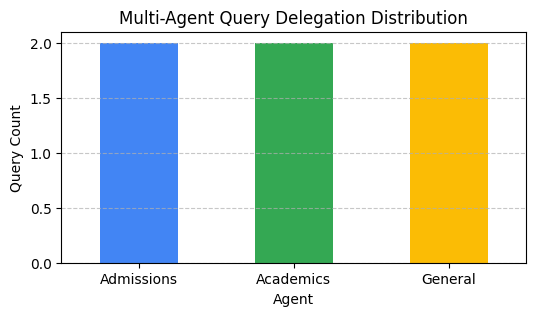

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Test suite of sample questions
test_queries = [
    "When is the application deadline for freshers?",
    "What subjects are covered under Data Structures?",
    "Where is the campus cafeteria located?",
    "How much is the tuition fee for engineering?",
    "What is the policy for short attendance?",
    "Good morning! How can you help me?"
]

execution_logs = []

for q in test_queries:
    # Get routing decisions
    cat = router_chain.invoke(q).strip().lower()
    resp = multi_agent_system.invoke(q)
    execution_logs.append({"Query": q, "Assigned Agent": cat.capitalize(), "Response": resp[:60] + "..."})

# Display structured log as DataFrame
df_logs = pd.DataFrame(execution_logs)
display(df_logs)

# Visualizing routing distribution
plt.figure(figsize=(6, 3))
df_logs['Assigned Agent'].value_counts().plot(kind='bar', color=['#4285F4', '#34A853', '#FBBC05'])
plt.title("Multi-Agent Query Delegation Distribution")
plt.xlabel("Agent")
plt.ylabel("Query Count")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [40]:
!pip install -q gradio

import gradio as gr

def respond(message, history):
    # Retrieve category for status logging
    category = router_chain.invoke(message).strip().upper()
    bot_response = multi_agent_system.invoke(message)
    formatted_response = f"**[Routed to: {category} AGENT]**\n\n{bot_response}"
    return formatted_response

# Launch interactive Gradio chatbot directly inside Colab
gr.ChatInterface(
    fn=respond,
    title="🎓 Multi-Agent College Enquiry Assistant",
    description="Ask questions about Admissions, Academics, or General Campus details. LCEL Supervisor routes your query to the relevant agent.",
    examples=[
        "What is the application deadline and fee?",
        "What courses are offered in Computer Engineering?",
        "What is the minimum attendance required?"
    ]
).launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://531a9e1a6ce07102c1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://531a9e1a6ce07102c1.gradio.live


In [41]:
from langchain_community.chat_message_histories import ChatMessageHistory
from langchain_core.chat_history import BaseChatMessageHistory
from langchain_core.runnables.history import RunnableWithMessageHistory

# Global dictionary to store session histories by session_id
store = {}

def get_session_history(session_id: str) -> BaseChatMessageHistory:
    """Retrieve or initialize chat history for a given session."""
    if session_id not in store:
        store[session_id] = ChatMessageHistory()
    return store[session_id]

In [46]:
from langchain_core.prompts import MessagesPlaceholder
from operator import itemgetter

# 1. Admissions Agent with Memory
admissions_prompt_mem = ChatPromptTemplate.from_messages([
    ("system", "You are the College Admissions Desk Agent. Answer questions strictly using the provided context.\n\nContext: {context}"),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

admissions_chain_mem = (
    {
        "context": itemgetter("question") | admissions_retriever | format_docs,
        "question": itemgetter("question"),
        "history": itemgetter("history")
    }
    | admissions_prompt_mem
    | llm
    | StrOutputParser()
)

# 2. Academics Agent with Memory
academics_prompt_mem = ChatPromptTemplate.from_messages([
    ("system", "You are the Academic Affairs Agent. Answer questions about curriculum, departments, and policy using the provided context.\n\nContext: {context}"),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

academics_chain_mem = (
    {
        "context": itemgetter("question") | academics_retriever | format_docs,
        "question": itemgetter("question"),
        "history": itemgetter("history")
    }
    | academics_prompt_mem
    | llm
    | StrOutputParser()
)

# 3. General Agent with Memory
general_prompt_mem = ChatPromptTemplate.from_messages([
    ("system", "You are the College Welcome Desk Agent. Help with general queries, greetings, and campus info politely."),
    MessagesPlaceholder(variable_name="history"),
    ("human", "{question}")
])

general_chain_mem = general_prompt_mem | llm | StrOutputParser()




In [47]:
def route_and_execute_mem(info):
    category = info['category'].strip().lower()
    question = info['question']
    history = info['history']

    print(f"📍 [Supervisor Router] Category: [{category.upper()}] | Context Length: {len(history)} messages")

    # Pass input and history payload to chosen worker chain
    chain_input = {"question": question, "history": history}

    if "admission" in category:
        return admissions_chain_mem.invoke(chain_input)
    elif "academic" in category:
        return academics_chain_mem.invoke(chain_input)
    else:
        return general_chain_mem.invoke(chain_input)

# Base chain taking history into account
base_multi_agent_chain = (
    {
        "category": router_chain,
        "question": RunnablePassthrough(),
        "history": RunnableLambda(lambda x: x.get("history", []))
    }
    | RunnableLambda(route_and_execute_mem)
)

# Runnable wrapper injecting memory history via session_id
with_message_history = RunnableWithMessageHistory(
    base_multi_agent_chain,
    get_session_history,
    input_messages_key="question",
    history_messages_key="history"
)

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3553: LangChainPendingDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [44]:
session_config = {"configurable": {"session_id": "student_session_101"}}

# Turn 1: Introduce user details to General Agent
q1 = "Hi, my name is Shikshita and I am applying for Computer Science."
print(f"User: {q1}")
res1 = with_message_history.invoke({"question": q1}, config=session_config)
print(f"Agent Response:\n{res1}\n" + "="*60)

# Turn 2: Follow-up routed to Admissions Agent (using implicit "my course" from context)
q2 = "What is the tuition fee for my course?"
print(f"User: {q2}")
res2 = with_message_history.invoke({"question": q2}, config=session_config)
print(f"Agent Response:\n{res2}\n" + "="*60)

# Turn 3: Contextual reference back to name & course
q3 = "Can you remind me of my name and what program I'm interested in?"
print(f"User: {q3}")
res3 = with_message_history.invoke({"question": q3}, config=session_config)
print(f"Agent Response:\n{res3}\n" + "="*60)

User: Hi, my name is Shikshita and I am applying for Computer Science.
📍 [Supervisor Router] Category: [ADMISSIONS] | Context Length: 0 messages


AttributeError: 'dict' object has no attribute 'replace'

In [50]:
import gradio as gr

# Predict handler communicating with LCEL memory chain
def custom_predict(message, history):
    session_id = "gradio_colab_session"
    config = {"configurable": {"session_id": session_id}}

    # 1. Classify route for UI display tag
    category = router_chain.invoke(message).strip().upper()

    # 2. Invoke LCEL system with session memory
    bot_response = with_message_history.invoke(
        {"question": message},
        config=config
    )

    return f"**[Agent: {category}]**\n\n{bot_response}"

def clear_session_memory():
    """Clear memory in global store when reset is clicked."""
    if "gradio_colab_session" in store:
        del store["gradio_colab_session"]
    return []

# Build modern Blocks layout
with gr.Blocks(title="Multi-Agent College Chatbot") as demo:
    gr.Markdown(
        """
        # 🎓 Multi-Agent College Enquiry Assistant (LCEL + RAG + Memory)
        *Powered by **LangChain**, **FAISS**, **Groq/Llama-3**, and **RunnableWithMessageHistory**.*
        """
    )

    chatbot = gr.Chatbot(height=450)
    msg = gr.Textbox(placeholder="Ask about admissions, fees, or courses...", label="Student Query")

    with gr.Row():
        submit_btn = gr.Button("Submit", variant="primary")
        clear_btn = gr.Button("Clear Chat & Reset Memory")

    def user_turn(user_message, history):
        if not history:
            history = []
        return "", history + [{"role": "user", "content": user_message}]

    def bot_turn(history):
        user_message = history[-1]["content"]
        # Pass conversation context up to current turn
        bot_response = custom_predict(user_message, history[:-1])
        history.append({"role": "assistant", "content": bot_response})
        return history

    # Connect UI triggers
    msg.submit(user_turn, [msg, chatbot], [msg, chatbot], queue=False).then(
        bot_turn, chatbot, chatbot
    )
    submit_btn.click(user_turn, [msg, chatbot], [msg, chatbot], queue=False).then(
        bot_turn, chatbot, chatbot
    )

    clear_btn.click(clear_session_memory, None, chatbot, queue=False)

# Pass theme parameter during launch
demo.launch(share=True, debug=True, theme=gr.themes.Soft())

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://91f89019936bbfc0c4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://91f89019936bbfc0c4.gradio.live


In [51]:
!pip install -q rank_bm25

from langchain_community.retrievers import BM25Retriever
from langchain.retrievers import EnsembleRetriever

def build_ensemble_retriever(file_path):
    with open(file_path, "r") as f:
        text = f.read()

    splitter = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=20)
    docs = splitter.create_documents([text])

    # 1. Keyword-based BM25 Retriever
    bm25_retriever = BM25Retriever.from_documents(docs)
    bm25_retriever.k = 2

    # 2. Dense Vector FAISS Retriever
    faiss_db = FAISS.from_documents(docs, embeddings)
    faiss_retriever = faiss_db.as_retriever(search_kwargs={"k": 2})

    # 3. Hybrid Ensemble Retriever (50% keyword, 50% semantic vector)
    ensemble_retriever = EnsembleRetriever(
        retrievers=[bm25_retriever, faiss_retriever],
        weights=[0.5, 0.5]
    )
    return ensemble_retriever

# Re-initialize retrievers with hybrid search capability
admissions_retriever = build_ensemble_retriever("admissions.txt")
academics_retriever = build_ensemble_retriever("academics.txt")

print("✅ Hybrid BM25 + FAISS Ensemble Retrievers initialized successfully!")

✅ Hybrid BM25 + FAISS Ensemble Retrievers initialized successfully!
